In [ ]:
!pip install -q kagglehub

import kagglehub, pandas as pd, numpy as np, random, os
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")
print(os.listdir(path))

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
['complaints_processed.csv']


In [ ]:
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.isna().sum())

(162421, 3)
['Unnamed: 0', 'product', 'narrative']
   Unnamed: 0           product  \
0           0       credit_card   
1           1       credit_card   
2           2    retail_banking   
3           3  credit_reporting   
4           4  credit_reporting   

                                           narrative  
0  purchase order day shipping amount receive pro...  
1  forwarded message date tue subject please inve...  
2  forwarded message cc sent friday pdt subject f...  
3  payment history missing credit report speciali...  
4  payment history missing credit report made mis...  
Unnamed: 0     0
product        0
narrative     10
dtype: int64


In [ ]:
df = df.drop(columns=["Unnamed: 0"])

# 1) null / empty
print("Null narratives:", df["narrative"].isna().sum())
df = df.dropna(subset=["narrative"])
df["narrative"] = df["narrative"].astype(str).str.strip()
df = df[df["narrative"] != ""]

# 2) exact duplicate rows (same text + same label)
n0 = len(df)
df = df.drop_duplicates(subset=["narrative", "product"])
print("Removed exact duplicates:", n0 - len(df))

# 3) conflicting labels (same text, different labels) -> remove all of them
label_counts = df.groupby("narrative")["product"].nunique()
conflicting = label_counts[label_counts > 1].index
print("Conflicting texts:", len(conflicting))
df = df[~df["narrative"].isin(conflicting)].reset_index(drop=True)

print("Final shape:", df.shape)

Null narratives: 10
Removed exact duplicates: 37735
Conflicting texts: 172
Final shape: (124300, 2)


product
credit_reporting       56172
debt_collection        20998
mortgages_and_loans    18701
credit_card            14963
retail_banking         13466
Name: count, dtype: int64
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.05
credit_card            12.04
retail_banking         10.83
Name: count, dtype: float64


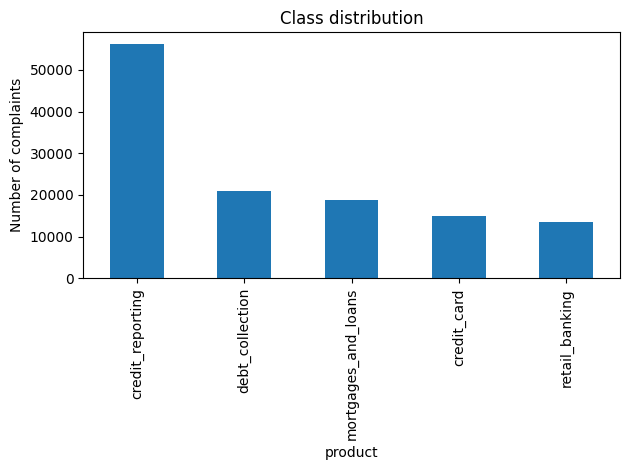

count    124300.000000
mean         87.212663
std         110.978938
min           1.000000
50%          58.000000
75%         104.000000
90%         180.000000
95%         253.000000
99%         502.000000
max        2685.000000
Name: n_words, dtype: float64


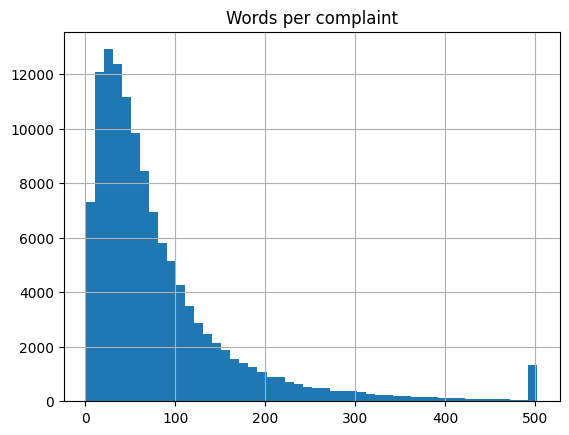

In [ ]:
import matplotlib.pyplot as plt

counts = df["product"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

counts.plot(kind="bar", title="Class distribution")
plt.ylabel("Number of complaints"); plt.tight_layout(); plt.show()

df["n_words"] = df["narrative"].str.split().str.len()
print(df["n_words"].describe(percentiles=[.5, .75, .9, .95, .99]))

df["n_words"].clip(upper=df["n_words"].quantile(.99)).hist(bins=50)
plt.title("Words per complaint"); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

le = LabelEncoder()
df["label"] = le.fit_transform(df["product"])
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print(dict(enumerate(class_names)))

train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print(len(train_df), len(val_df), len(test_df))
print(train_df["label"].value_counts(normalize=True).round(3).sort_index())
print(test_df["label"].value_counts(normalize=True).round(3).sort_index())

# class weights from TRAIN only
weights = compute_class_weight("balanced",
                               classes=np.arange(NUM_CLASSES),
                               y=train_df["label"])
class_weight = dict(enumerate(weights))
print(class_weight)

{0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}
99440 12430 12430
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64
label
0    0.120
1    0.452
2    0.169
3    0.150
4    0.108
Name: proportion, dtype: float64
{0: np.float64(1.6614870509607351), 1: np.float64(0.44256531220793094), 2: np.float64(1.1839504702940826), 3: np.float64(1.329322906222846), 4: np.float64(1.8460967232897056)}


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 30000
MAX_LEN = 250

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["narrative"])

def encode(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train = encode(train_df["narrative"]); y_train = train_df["label"].values
X_val   = encode(val_df["narrative"]);   y_val   = val_df["label"].values
X_test  = encode(test_df["narrative"]);  y_test  = test_df["label"].values

print(X_train.shape, X_val.shape, X_test.shape)
print("Total vocab found:", len(tokenizer.word_index))

# how much text we lose by truncation
lens = train_df["narrative"].str.split().str.len()
print("Truncated texts: %.1f%%" % ((lens > MAX_LEN).mean() * 100))

(99440, 250) (12430, 250) (12430, 250)
Total vocab found: 41669
Truncated texts: 5.1%


In [ ]:
print("build_model" in globals(), "train_and_eval" in globals())
print("X_train" in globals(), "class_weight" in globals())

False False
True True


Model: "simple_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,881,477 (14.81 MB)

 Trainable params: 3,881,477 (14.81 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
389/389 - 24s - 63ms/step - accuracy: 0.5456 - loss: 1.0322 - val_accuracy: 0.7485 - val_loss: 0.7335
Epoch 2/15
389/389 - 13s - 34ms/step - accuracy: 0.7630 - loss: 0.7166 - val_accuracy: 0.7724 - val_loss: 0.7284
Epoch 3/15
389/389 - 20s - 50ms/step - accuracy: 0.7836 - loss: 0.6700 - val_accuracy: 0.7891 - val_loss: 0.6688
Epoch 4/15
389/389 - 12s - 30ms/step - accuracy: 0.7998 - loss: 0.6058 - val_accuracy: 0.7926 - val_loss: 0.6578
Epoch 5/15
389/389 - 12s - 31ms/step - accuracy: 0.8095 - loss: 0.5720 - val_accuracy: 0.7957 - val_loss: 0.6546
Epoch 6/15
389/389 - 12s - 31ms/step - accuracy: 0.8212 - loss: 0.5323 - val_accuracy: 0.7740 - val_loss: 0.6799
Epoch 7/15
389/389 - 12s - 31ms/step - accuracy: 0.8330 - loss: 0.4775 - val_accuracy: 0.7979 - val_loss: 0.6717
Epoch 8/15
389/389 - 12s - 31ms/step - accuracy: 0.8462 - loss: 0.4245 - val_accuracy: 0.7821 - val_loss: 0.7184
                     precision    recall  f1-score   support

        credit_card     0.6464    

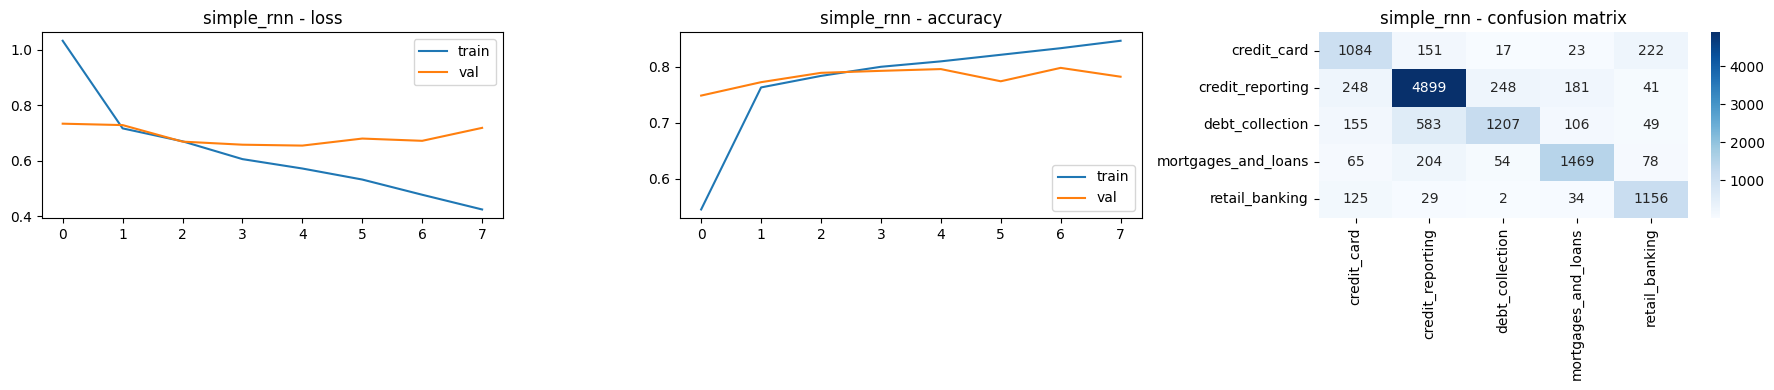

In [ ]:
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
import time, seaborn as sns, matplotlib.pyplot as plt

class_weight = {k: float(v) for k, v in class_weight.items()}
results = {}

def build_model(rnn_layer, name):
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, 128, mask_zero=True),
        rnn_layer,
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model

def train_and_eval(model, name, epochs=15, batch_size=256):
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                 restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=batch_size,
                     class_weight=class_weight, callbacks=[es], verbose=2)
    train_min = (time.time() - t0) / 60

    t0 = time.time()
    probs = model.predict(X_test, batch_size=512, verbose=0)
    infer_ms = (time.time() - t0) / len(X_test) * 1000
    preds = probs.argmax(axis=1)

    results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "macro_f1": f1_score(y_test, preds, average="macro"),
        "weighted_f1": f1_score(y_test, preds, average="weighted"),
        "params_M": model.count_params() / 1e6,
        "train_min": train_min,
        "infer_ms_per_sample": infer_ms,
    }

    print(classification_report(y_test, preds, target_names=class_names, digits=4))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="val")
    ax[0].set_title(f"{name} - loss"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="val")
    ax[1].set_title(f"{name} - accuracy"); ax[1].legend()
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[2],
                xticklabels=class_names, yticklabels=class_names)
    ax[2].set_title(f"{name} - confusion matrix")
    plt.tight_layout(); plt.show()

    model.save(f"{name}.keras")
    return preds

# ---- SimpleRNN ----
model_rnn = build_model(layers.SimpleRNN(128), "simple_rnn")
model_rnn.summary()
preds_rnn = train_and_eval(model_rnn, "simple_rnn")


Epoch 1/15
389/389 - 16s - 42ms/step - accuracy: 0.7180 - loss: 0.7805 - val_accuracy: 0.7873 - val_loss: 0.6353
Epoch 2/15
389/389 - 9s - 24ms/step - accuracy: 0.8226 - loss: 0.5382 - val_accuracy: 0.8166 - val_loss: 0.5545
Epoch 3/15
389/389 - 9s - 23ms/step - accuracy: 0.8410 - loss: 0.4678 - val_accuracy: 0.8065 - val_loss: 0.5601
Epoch 4/15
389/389 - 10s - 25ms/step - accuracy: 0.8514 - loss: 0.4238 - val_accuracy: 0.8248 - val_loss: 0.5098
Epoch 5/15
389/389 - 9s - 24ms/step - accuracy: 0.8607 - loss: 0.3891 - val_accuracy: 0.8278 - val_loss: 0.5098
Epoch 6/15
389/389 - 10s - 26ms/step - accuracy: 0.8702 - loss: 0.3621 - val_accuracy: 0.8329 - val_loss: 0.4987
Epoch 7/15
389/389 - 9s - 23ms/step - accuracy: 0.8776 - loss: 0.3282 - val_accuracy: 0.8270 - val_loss: 0.5250
Epoch 8/15
389/389 - 9s - 24ms/step - accuracy: 0.8829 - loss: 0.3098 - val_accuracy: 0.8260 - val_loss: 0.5338
Epoch 9/15
389/389 - 9s - 24ms/step - accuracy: 0.8864 - loss: 0.2966 - val_accuracy: 0.8216 - val_lo

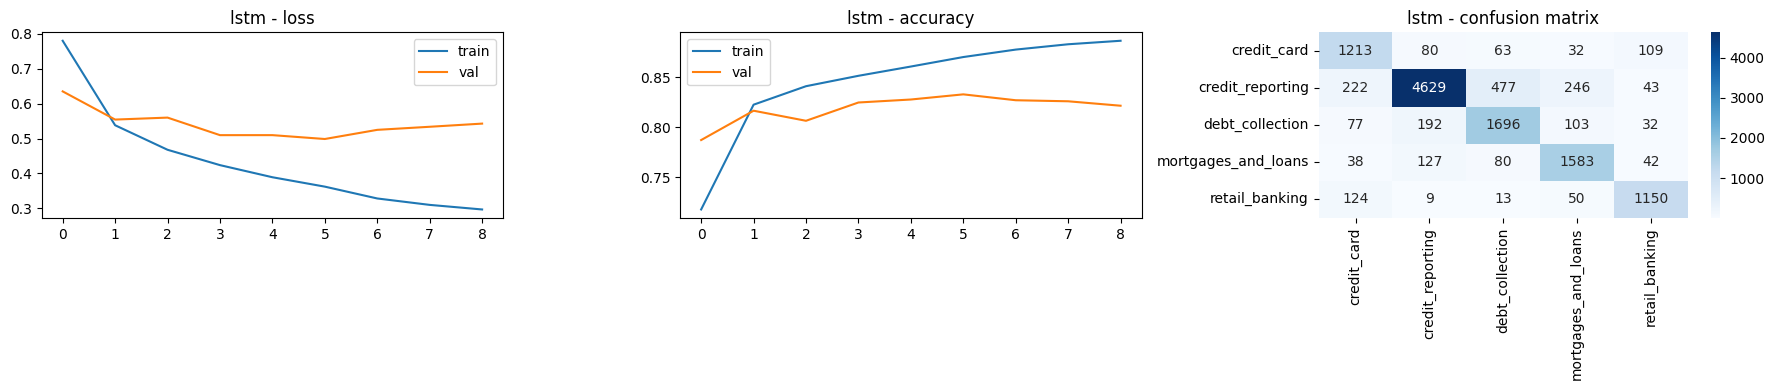

Epoch 1/15
389/389 - 11s - 28ms/step - accuracy: 0.7060 - loss: 0.7625 - val_accuracy: 0.8339 - val_loss: 0.4872
Epoch 2/15
389/389 - 9s - 22ms/step - accuracy: 0.8364 - loss: 0.4544 - val_accuracy: 0.8301 - val_loss: 0.4851
Epoch 3/15
389/389 - 9s - 22ms/step - accuracy: 0.8544 - loss: 0.3904 - val_accuracy: 0.8345 - val_loss: 0.4677
Epoch 4/15
389/389 - 9s - 23ms/step - accuracy: 0.8671 - loss: 0.3508 - val_accuracy: 0.8270 - val_loss: 0.4883
Epoch 5/15
389/389 - 9s - 23ms/step - accuracy: 0.8766 - loss: 0.3183 - val_accuracy: 0.8249 - val_loss: 0.4970
Epoch 6/15
389/389 - 8s - 22ms/step - accuracy: 0.8857 - loss: 0.2885 - val_accuracy: 0.8253 - val_loss: 0.5126
                     precision    recall  f1-score   support

        credit_card     0.7398    0.8357    0.7848      1497
   credit_reporting     0.9371    0.8017    0.8641      5617
    debt_collection     0.7230    0.8267    0.7714      2100
mortgages_and_loans     0.7871    0.8717    0.8272      1870
     retail_banking  

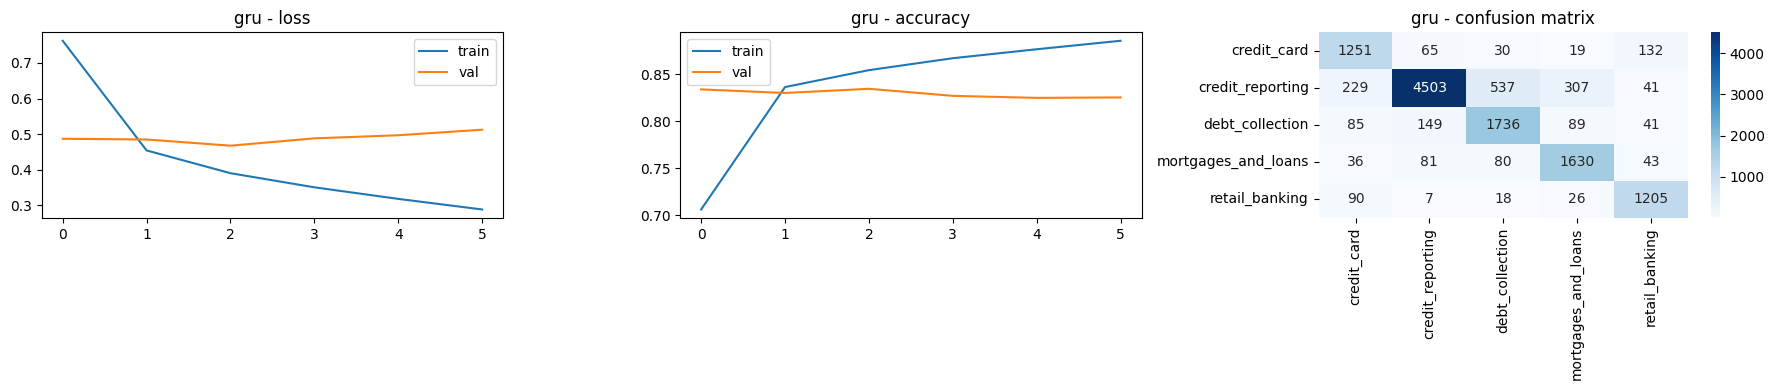

In [ ]:
# ---- LSTM ----
model_lstm = build_model(layers.LSTM(128), "lstm")
preds_lstm = train_and_eval(model_lstm, "lstm")

# ---- GRU ----
model_gru = build_model(layers.GRU(128), "gru")
preds_gru = train_and_eval(model_gru, "gru")

In [ ]:
import json, pickle
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
with open("labels.json", "w") as f:
    json.dump(class_names, f)

pd.DataFrame(results).T.round(4).to_csv("results_so_far.csv")
print(pd.DataFrame(results).T.round(4))

            accuracy  macro_f1  weighted_f1  params_M  train_min  \
simple_rnn    0.7896    0.7598       0.7868    3.8815     1.9529   
lstm          0.8263    0.8120       0.8283    3.9802     1.5349   
gru           0.8307    0.8212       0.8327    3.9477     0.9110   

            infer_ms_per_sample  
simple_rnn               0.2094  
lstm                     0.0454  
gru                      0.0547  


In [ ]:
import json, pickle
with open("tokenizer.pkl", "wb") as f: pickle.dump(tokenizer, f)
with open("labels.json", "w") as f: json.dump(class_names, f)
pd.DataFrame(results).T.round(4).to_csv("results_so_far.csv")
print(pd.DataFrame(results).T.round(4))

            accuracy  macro_f1  weighted_f1  params_M  train_min  \
simple_rnn    0.7896    0.7598       0.7868    3.8815     1.9529   
lstm          0.8263    0.8120       0.8283    3.9802     1.5349   
gru           0.8307    0.8212       0.8327    3.9477     0.9110   

            infer_ms_per_sample  
simple_rnn               0.2094  
lstm                     0.0454  
gru                      0.0547  


In [ ]:
print("distilbert" in results)

False


In [ ]:
import os
print(os.path.exists("complaint_model"))
print(os.path.exists("complaint_model_zip.zip"))
if os.path.exists("complaint_model"):
    print(os.listdir("complaint_model"))

False
False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "model.safetensors" in files:
        fp = os.path.join(root, "model.safetensors")
        print(f"{os.path.getsize(fp)/1e6:.1f} MB  {root}")
        print("   ", sorted(files))

Mounted at /content/drive
267.8 MB  /content/drive/MyDrive/complaint_deploy/hf
    ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']
267.8 MB  /content/drive/MyDrive/complaint_deploy/deploy/hf
    ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


In [ ]:
args = TrainingArguments(
    output_dir="distilbert_out",
    eval_strategy="epoch", save_strategy="epoch",
    learning_rate=2e-5, weight_decay=0.01, warmup_steps=900,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3, fp16=True,
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    save_total_limit=1, report_to="none", seed=SEED)

trainer = WeightedTrainer(model=model_bert, args=args,
                          train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=collator, compute_metrics=compute_metrics)

t0 = time.time()
trainer.train()
train_min = (time.time() - t0) / 60

# ---- test evaluation, same metrics as the other models ----
t0 = time.time()
out = trainer.predict(test_ds)
infer_ms = (time.time() - t0) / len(test_ds) * 1000
preds_bert = out.predictions.argmax(-1)

results["distilbert"] = {
    "accuracy": accuracy_score(y_test, preds_bert),
    "macro_f1": f1_score(y_test, preds_bert, average="macro"),
    "weighted_f1": f1_score(y_test, preds_bert, average="weighted"),
    "params_M": sum(p.numel() for p in model_bert.parameters()) / 1e6,
    "train_min": train_min,
    "infer_ms_per_sample": infer_ms,
}
print(classification_report(y_test, preds_bert, target_names=class_names, digits=4))

cm = confusion_matrix(y_test, preds_bert)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("distilbert - confusion matrix"); plt.show()

trainer.save_model("complaint_model")
hf_tokenizer.save_pretrained("complaint_model")
print(pd.DataFrame(results).T.round(4))

NameError: name 'TrainingArguments' is not defined

In [ ]:
!pip install -q transformers huggingface_hub
from huggingface_hub import login
from transformers import AutoTokenizer, AutoModelForSequenceClassification
login()   # الصقي Write token في الخانة

MODEL_DIR = "/content/drive/MyDrive/complaint_deploy/hf"
REPO = "YOUR_USERNAME/complaint-distilbert"

m = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)
t = AutoTokenizer.from_pretrained(MODEL_DIR)
print(m.config.id2label)
print(sum(p.numel() for p in m.parameters()) / 1e6)

m.push_to_hub(REPO); t.push_to_hub(REPO)
print("https://huggingface.co/" + REPO)

Loading weights:   0%|          | 0/104 [00:02<?, ?it/s]

{0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}
66.957317


HfHubHTTPError: Client error '401 Unauthorized' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6af5ae13-4916a86335b5753739e01b62;f0a15151-f631-4ab2-a04f-c4a90cb49acb)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/401

Invalid username or password.

In [ ]:
import shutil, json
from sklearn.metrics import confusion_matrix

# 1) save results + comparison chart
res = pd.DataFrame(results).T.round(4)
res.to_csv("results_final.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res[["accuracy", "macro_f1"]].plot(kind="bar", ax=ax[0], ylim=(0.7, 0.9))
ax[0].set_title("Accuracy & Macro-F1"); ax[0].tick_params(axis="x", rotation=0)
res["infer_ms_per_sample"].plot(kind="bar", ax=ax[1], logy=True, color="gray")
ax[1].set_title("Inference time per sample (ms, log scale)")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

# 2) most frequent confusions of the best model
cm = confusion_matrix(y_test, preds_bert)
pairs = [(class_names[i], class_names[j], cm[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
pairs.sort(key=lambda x: -x[2])
print("Top confusions (true -> predicted, count):")
for t, p, c in pairs[:5]:
    print(f"  {t} -> {p}: {c}")

# 3) sample of misclassified complaints
errs = test_df.copy()
errs["pred"] = [class_names[i] for i in preds_bert]
errs = errs[errs["label"].values != preds_bert]
pd.set_option("display.max_colwidth", 300)
print("\nTotal errors:", len(errs))
print(errs[["product", "pred", "narrative"]].sample(8, random_state=SEED).to_string())

# 4) zip the deployment files for download
shutil.make_archive("complaint_model_zip", "zip", "complaint_model")

In [ ]:
import re, nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords", quiet=True); nltk.download("wordnet", quiet=True)

STOP = set(stopwords.words("english"))
lemm = WordNetLemmatizer()

def clean_text(text, lemmatize=True):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in STOP]
    if lemmatize:
        words = [lemm.lemmatize(w) for w in words]
    return " ".join(words)

raw = "I called Capital One 3 times on 05/12/2020!!! They NEVER fixed the wrong charge on my account."
print("RAW  :", raw)
print("CLEAN:", clean_text(raw))

sample = train_df["narrative"].sample(2000, random_state=SEED)
print(f"Identical after re-cleaning: {(sample == sample.apply(clean_text)).mean():.1%}")

In [ ]:
import torch
model_bert.eval()

def predict_complaint(text):
    inputs = hf_tokenizer(clean_text(text), truncation=True, max_length=256,
                          return_tensors="pt").to(model_bert.device)
    with torch.no_grad():
        probs = torch.softmax(model_bert(**inputs).logits, dim=-1)[0].cpu().numpy()
    return {class_names[i]: float(p) for i, p in enumerate(probs)}

new_complaints = [
    "A debt collector keeps calling me about a loan I already paid off and threatens to sue.",
    "There is an incorrect late payment on my credit report and the bureau refuses to remove it.",
    "My bank charged me overdraft fees even though my account had enough money.",
    "I was approved for a mortgage but the lender keeps delaying the closing and changed the rate.",
]
for c in new_complaints:
    p = predict_complaint(c)
    top = max(p, key=p.get)
    print(f"{top} ({p[top]:.1%}) <- {c[:70]}...")

In [ ]:
diff = sample[sample != sample.apply(clean_text)].head(5)
for t in diff:
    print("DATA :", t[:150])
    print("OURS :", clean_text(t)[:150])
    print()

In [ ]:
from sklearn.metrics import precision_score, recall_score

all_preds = {"simple_rnn": preds_rnn, "lstm": preds_lstm,
             "gru": preds_gru, "distilbert": preds_bert}

for name, p in all_preds.items():
    results[name]["macro_precision"] = precision_score(y_test, p, average="macro")
    results[name]["macro_recall"]    = recall_score(y_test, p, average="macro")

final = pd.DataFrame(results).T[["accuracy", "macro_precision", "macro_recall",
                                 "macro_f1", "params_M", "train_min",
                                 "infer_ms_per_sample"]].round(4)
print(final)
final.to_csv("results_final.csv")

In [ ]:
!pip install -q gradio
import gradio as gr

def gradio_predict(text):
    if not text or not text.strip():
        return {}
    return predict_complaint(text)

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Textbox(lines=8, label="Complaint narrative"),
    outputs=gr.Label(num_top_classes=5, label="Predicted category & confidence"),
    title="Consumer Complaint Classifier",
    description="DistilBERT fine-tuned on consumer complaints (5 categories).",
)
demo.launch(share=True, debug=True)

In [ ]:
from huggingface_hub import login
login()   # هيفتح خانة، الصقي الـ token فيها

REPO = "mai-data-ai/complaint-distilbert"   # غيّري YOUR_USERNAME لاسم حسابك
model_bert.push_to_hub(REPO)
hf_tokenizer.push_to_hub(REPO)